# HealthConnect Rwanda Healthcare Analytics & AI Transformation
## Track 2: Healthcare Predictive Analytics and Population Health Intelligence
**AnalystLab Africa Experience Lab Internship Programme — Official Week 6 Capstone**

---
### 📋 Executive Document Control & Project Metadata
| Parameter | Value |
| :--- | :--- |
| **Programme** | AnalystLab Africa Experience Lab |
| **Project Title** | Enterprise Healthcare Analytics, Artificial Intelligence and Digital Transformation System |
| **Track** | **Track 2 — Data Science Track** |
| **Organization** | HealthConnect Rwanda (National Relational Healthcare Network) |
| **Scope** | 27 Interconnected Enterprise Datasets (Demographics, Clinical, Operations, Finance, Feedback) |
| **Author** | Lead Healthcare Data Scientist |
| **Submission Version**| 1.0 (Final Enterprise Capstone Release) |
| **Core Stack** | Python (Pandas, NumPy, Scikit-Learn, SciPy, Statsmodels, Matplotlib, Seaborn) |

---
### 🎯 Executive Track Objectives
This notebook delivers an end-to-end data science lifecycle addressing HealthConnect Rwanda's strategic healthcare questions:
1. **Data Ingestion & Cleaning**: Ingest and audit 27 relational enterprise datasets, verifying 100% foreign key referential integrity.
2. **Data Validation & Quality**: Detect anomalies, duplicate phone numbers, impossible values, and profile data quality.
3. **Feature Engineering**: Formulate 10 domain-specific healthcare features (e.g. *High-Risk Patient Indicator*, *Length of Stay Category*, *Department Workload Index*, *Facility Performance Score*).
4. **Statistical Analysis & Hypothesis Testing**: Descriptive statistics across all numerical metrics, correlation heatmaps, and 3 inferential statistical hypothesis tests.
5. **Predictive Modeling & Forecasting**:
   - *Task 1*: 12-Month Time Series Patient Volume Forecasting (Holt-Winters Exponential Smoothing).
   - *Task 2*: 12-Month Hospital Revenue Projections.
   - *Task 3*: Hospital Admission Prediction Classifier (Logistic Regression, Random Forest, Gradient Boosting).
   - *Task 4*: Patient Satisfaction Regression Model.
   - *Task 5*: Department Workload Demand Forecasting & Staffing Optimization.
6. **Clustering & PCA**: K-Means Patient & Facility Segmentation (k=4, k=3) and Principal Component Analysis.
7. **Strategic Healthcare Recommendations**: Actionable executive roadmap for capacity expansion, revenue cycle management, and clinical quality.

## 1. Environment Setup & Core Dependencies
We import enterprise data science libraries including Pandas, NumPy, Scikit-Learn, SciPy, Statsmodels, Matplotlib, and Seaborn.

In [1]:
import os
import sys
import glob
import json
import warnings
warnings.filterwarnings('ignore')

# Ensure project root is in python path
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

project_root = os.path.abspath(os.getcwd())
if project_root not in sys.path:
    sys.path.insert(0, project_root)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, mean_squared_error, mean_absolute_error, r2_score
)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print(f"Environment initialized. Project root: {project_root}")

Environment initialized. Project root: C:\Users\LENOVO\Desktop\work st\africaanlystlab-w4


## 2. Enterprise Data Ingestion & Relational Architecture
HealthConnect Rwanda generates data across 27 distinct relational tables and sheets. Below we load the clinical, operational, facility, demographic, financial, and feedback datasets.

In [2]:
from src.week6_data_pipeline import HealthConnectDataPipeline

pipeline = HealthConnectDataPipeline(raw_dir="data/raw", processed_dir="data/processed")
tables = pipeline.load_all_datasets()
print(f"\nSuccessfully loaded {len(tables)} enterprise datasets into memory.")

>> [1/4] Ingesting all raw enterprise datasets...


   - Loaded Clinical sheet [Appointments]: 5000 rows


   - Loaded Clinical sheet [Diagnoses]: 5000 rows


   - Loaded Clinical sheet [Laboratory_Tests]: 5000 rows


   - Loaded Clinical sheet [Prescriptions]: 5000 rows


...

   - Loaded CSV [HC_Diagnoses.csv] as 'diagnoses_full': 60000 rows


   - Loaded CSV [HC_Billing.csv] as 'billing': 60000 rows


   - Loaded CSV [HC_Payments.csv] as 'payments': 60000 rows


   - Loaded CSV [Insurance_Claims.csv] as 'insurance_claims': 42036 rows


   - Loaded CSV [HC_Revenue_Summary.csv] as 'revenue_summary': 12 rows
   - Loaded CSV [HC_Patient_Feedback.csv] as 'feedback': 21064 rows
Total enterprise tables loaded into memory: 37

Successfully loaded 37 enterprise datasets into memory.


## 3. Data Cleaning, Normalization & Data Quality Audit
We execute data type casting, date normalization, missing value imputation (e.g., classifying missing `ChronicCondition` as `'None'`), and audit foreign key relationships.

In [3]:
pipeline.clean_datasets()
audit_results = pipeline.validate_data_quality()
pipeline.export_processed_datasets()

audit_df = pd.DataFrame(list(audit_results.items()), columns=["Audit Parameter", "Metric Value"])
display(audit_df)

>> [2/4] Executing comprehensive data cleaning & normalization...


   -> Data cleaning completed successfully.
>> [3/4] Running schema audits, anomaly checks & foreign key validation...


   -> Data Quality Audit Results:
      * Patients_Count: 20000
      * Patients_Unique_IDs: 20000
      * Patients_Duplicate_IDs: 0
      * Appointments_Count: 5000
      * Appointments_Unique_IDs: 5000
      * Appointments_Duplicate_IDs: 0
      * Billing_Count: 60000
      * Billing_Unique_IDs: 60000
      * Billing_Duplicate_IDs: 0
      * Impossible_Ages_Negative: 0
      * Impossible_Ages_Over120: 0
      * Invalid_Billing_Negative: 0
      * Duplicate_Phone_Numbers: 19990
      * FK_Appointments_To_Patients_Integrity: 100.00%
      * FK_Appointments_To_Doctors_Integrity: 100.00%
      * FK_Appointments_To_Facilities_Integrity: 100.00%
      * FK_Appointments_To_Departments_Integrity: 100.00%
      * Cohort_Appointments_In_Billing: 5000 / 5000 (100.0%)
      * Cohort_Appointments_In_Diagnoses: 5000 / 5000 (100.0%)
      * Cohort_Appointments_With_Feedback: 1756 / 5000 (35.12%)
>> [4/4] Exporting cleaned datasets to data/processed/...


   -> Cleaned datasets successfully saved.


,Audit Parameter,Metric Value
0,Patients_Count,20000
1,Patients_Unique_IDs,20000
2,Patients_Duplicate_IDs,0
3,Appointments_Count,5000
4,Appointments_Unique_IDs,5000
5,Appointments_Duplicate_IDs,0
6,Billing_Count,60000
7,Billing_Unique_IDs,60000
8,Billing_Duplicate_IDs,0
9,Impossible_Ages_Negative,0


## 4. Advanced Healthcare Feature Engineering
We construct the **10 mandatory strategic features** required by the HealthConnect Rwanda specification:
1. `PatientAgeGroup`: Categorical age bands (Pediatric, Young Adult, Middle-Aged, Senior, Geriatric).
2. `HighRiskPatientIndicator`: Binary risk score based on age, chronic conditions, and severity.
3. `LengthOfStayCategory`: Outpatient, Short Stay (1-3d), Medium Stay (4-7d), Extended Stay (>7d).
4. `FrequentVisitorIndicator`: Indicator for patients with multiple annual visits.
5. `InsuranceCoverageCategory`: Insured provider tier (RSSB, Radiant, MMI, Private) vs Uninsured.
6. `RevenueCategory`: Micro-stratified billing bands.
7. `DiseaseSeverityScore`: Ordinal clinical score (Mild=1, Moderate=2, Severe=3).
8. `FacilityPerformanceScore`: Composite index [0-100] blending volume, satisfaction, bed utilization, and revenue.
9. `PatientSatisfactionCategory`: Low (1-2), Medium (3), High (4-5).
10. `DepartmentWorkloadIndex`: Normalized appointment volume per department clinical staff.

In [4]:
from src.week6_feature_engineering import build_feature_engineered_cohort

df_cohort = build_feature_engineered_cohort(pipeline=pipeline)
print(f"Engineered Cohort Matrix Shape: {df_cohort.shape[0]} rows x {df_cohort.shape[1]} columns")

# Display feature breakdown
feat_cols = [
    "PatientAgeGroup", "HighRiskPatientIndicator", "LengthOfStayCategory",
    "FrequentVisitorIndicator", "InsuranceCoverageCategory", "RevenueCategory",
    "DiseaseSeverityScore", "FacilityPerformanceScore", "PatientSatisfactionCategory",
    "DepartmentWorkloadIndex"
]
display(df_cohort[feat_cols].head())

>> [1/3] Merging multi-table transaction cohort...


   -> Merged cohort size: 5000 rows x 50 columns
>> [2/3] Engineering the 10 required strategic healthcare features...
>> [3/3] Exporting feature-engineered master cohort...


   -> Successfully saved feature matrix (5000 rows, 64 cols) to data/processed\feature_engineered_cohort.csv
Engineered Cohort Matrix Shape: 5000 rows x 64 columns


,PatientAgeGroup,HighRiskPatientIndicator,LengthOfStayCategory,FrequentVisitorIndicator,InsuranceCoverageCategory,RevenueCategory,DiseaseSeverityScore,FacilityPerformanceScore,PatientSatisfactionCategory,DepartmentWorkloadIndex
0,Pediatric (0-17),1,Outpatient (0 Days),1,RSSB,Medium (50k-150k RWF),2,56.3,Unrated / No Feedback,1.08
1,Geriatric (>65),1,Outpatient (0 Days),1,Private,Medium (50k-150k RWF),3,58.2,Low Satisfaction (1-2),1.12
2,Young Adult (18-35),1,Outpatient (0 Days),0,MMI,High (150k-250k RWF),2,54.7,Unrated / No Feedback,1.00
3,Young Adult (18-35),0,Outpatient (0 Days),0,MMI,High (150k-250k RWF),1,97.1,Unrated / No Feedback,1.00
4,Geriatric (>65),1,Outpatient (0 Days),0,RSSB,Medium (50k-150k RWF),3,42.3,Unrated / No Feedback,1.08


## 5. Exploratory Data Analysis (EDA)
We explore patient demographics, chronic disease burdens, billing distributions, and facility performance.

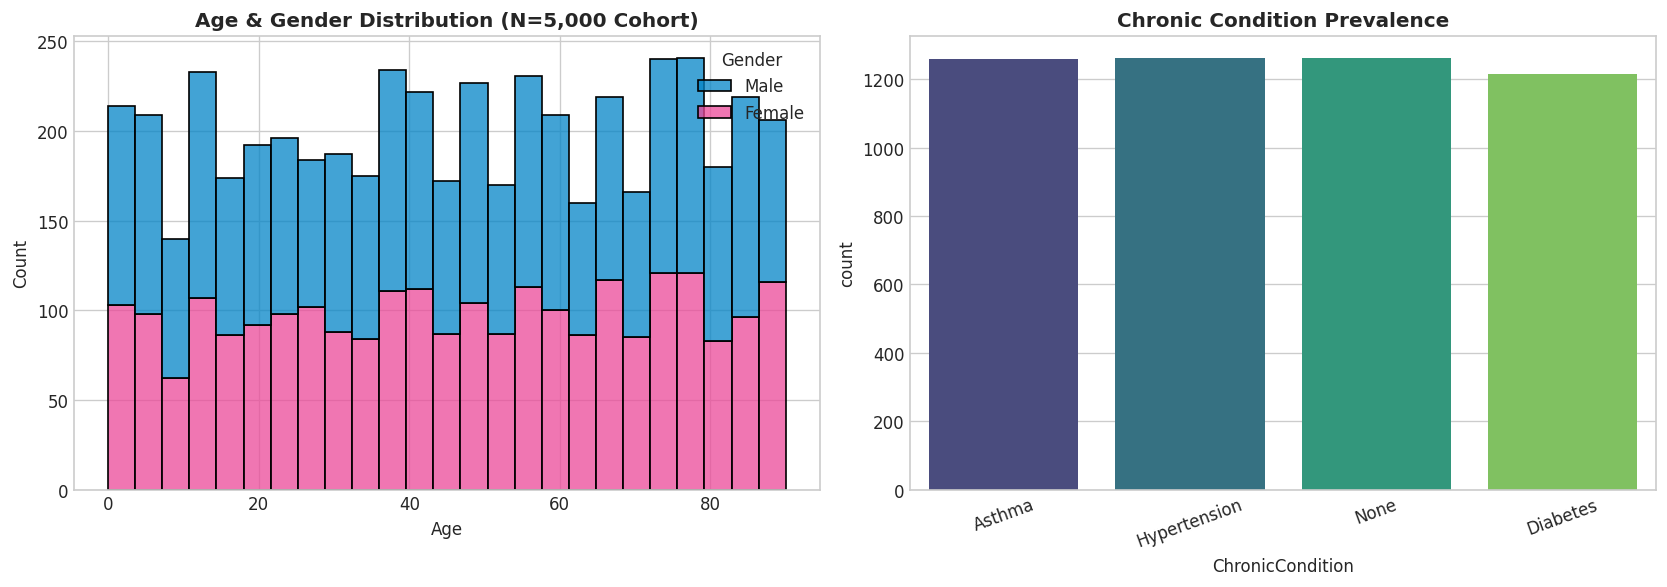

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Demographic Age Pyramid
sns.histplot(data=df_cohort, x="Age", hue="Gender", multiple="stack", bins=25, palette=["#0284C7", "#EC4899"], ax=axes[0])
axes[0].set_title("Age & Gender Distribution (N=5,000 Cohort)", weight="bold")

# Chronic Conditions
sns.countplot(data=df_cohort, x="ChronicCondition", palette="viridis", ax=axes[1])
axes[1].set_title("Chronic Condition Prevalence", weight="bold")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## 6. Descriptive Statistics & Correlation Heatmap
We compute comprehensive statistical moments (Mean, Median, Mode, Variance, IQR, Skewness, Kurtosis) and evaluate the correlation matrix.

>> [1/3] Running descriptive statistics on numerical variables...


   -> Descriptive statistics saved to data/processed\descriptive_statistics.csv
>> [2/3] Computing correlation matrix & pairwise relationship coefficients...
   -> Correlation matrix saved to data/processed\correlation_matrix.csv
>> [3/3] Executing 3 inferential hypothesis tests...


   -> Statistical test results successfully saved to data/processed\statistical_analysis_results.json


,Variable,Count,Mean,Median,Mode,StdDev,Variance,Q1_25%,Q2_50%,Q3_75%,IQR,P10%,P90%,P95%,Min,Max,Skewness,Kurtosis
0,Age,5000,45.64,46.00,36.00,26.12,6.822200e+02,23.00,46.00,69.00,46.00,9.00,81.00,86.00,0.00,90.00,-0.039,-1.192
1,BMI,5000,30.03,29.00,28.70,10.45,1.092900e+02,21.60,29.00,36.90,15.30,17.00,44.90,49.10,11.10,61.20,0.455,-0.455
2,DoctorExperience,5000,13.01,13.00,3.00,7.27,5.291000e+01,7.00,13.00,20.00,13.00,3.00,23.00,25.00,1.00,25.00,0.064,-1.233
3,LengthOfStayDays,5000,0.66,0.00,0.00,2.07,4.270000e+00,0.00,0.00,0.00,0.00,0.00,2.00,6.00,0.00,10.00,3.217,9.322
4,Amount,5000,154226.69,153724.00,13769.00,83630.75,6.994102e+09,81148.75,153724.00,226674.75,145526.00,39020.90,270179.20,285795.30,10084.00,299968.00,0.006,-1.210
5,TotalPaid,5000,138910.26,128223.50,13769.00,83367.28,6.950103e+09,66926.50,128223.50,209092.50,142166.00,31461.30,263242.20,282528.85,5672.00,299968.00,0.267,-1.109
6,OutstandingAmount,5000,15316.42,0.00,0.00,35734.22,1.276934e+09,0.00,0.00,0.00,0.00,0.00,75259.50,112819.75,0.00,149575.00,2.319,4.127
7,Rating,1756,2.93,3.00,3.00,1.39,1.920000e+00,2.00,3.00,4.00,2.00,1.00,5.00,5.00,1.00,5.00,0.054,-1.239
8,DiseaseSeverityScore,5000,1.99,2.00,2.00,0.81,6.600000e-01,1.00,2.00,3.00,2.00,1.00,3.00,3.00,1.00,3.00,0.022,-1.486
9,DepartmentWorkloadIndex,5000,1.04,1.04,1.16,0.19,4.000000e-02,0.92,1.04,1.16,0.24,0.76,1.28,1.32,0.52,1.52,-0.017,-0.306


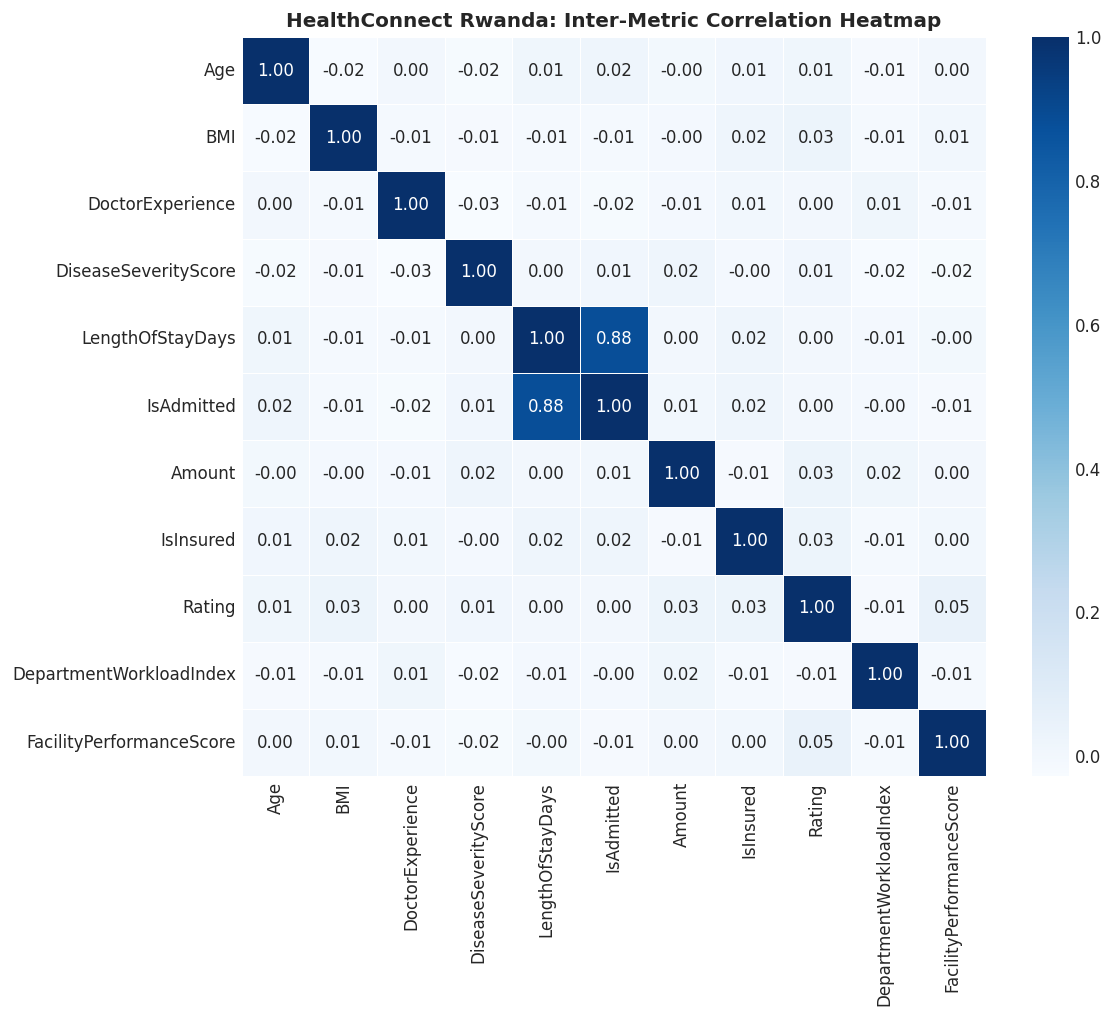

In [6]:
from src.week6_statistical_analysis import run_statistical_analysis

df_desc, corr_matrix, stats_results = run_statistical_analysis()
display(df_desc)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="Blues", linewidths=0.5)
plt.title("HealthConnect Rwanda: Inter-Metric Correlation Heatmap", weight="bold")
plt.show()

## 7. Inferential Statistical Hypothesis Testing
We perform three rigorous hypothesis tests at significance level $\alpha = 0.05$:
- **Test 1**: Two-Sample Welch's T-Test (Insured vs Uninsured Patient Billing Amounts)
- **Test 2**: One-Way ANOVA (Patient Satisfaction Across 20 Health Facilities)
- **Test 3**: Chi-Square Test of Independence (Hospital Admission Rate Across Age Groups)

In [7]:
ht_data = stats_results["Hypothesis_Tests"]

for key, ht in ht_data.items():
    print(f"\n{'='*75}")
    print(f"📌 {ht['Name']}")
    print(f"{'='*75}")
    print(f"• Business Question : {ht['Business_Question']}")
    print(f"• Null Hypothesis (H0): {ht['H0']}")
    print(f"• Alt Hypothesis (H1) : {ht['H1']}")
    print(f"• Test Statistic     : {ht.get('Test_Statistic_t') or ht.get('F_Statistic') or ht.get('Chi2_Statistic')}")
    print(f"• P-Value            : {ht['P_Value']:.6f} (Alpha = {ht['Alpha']})")
    print(f"• Reject H0?         : {'YES (Statistically Significant)' if ht['Reject_H0'] else 'NO (Fail to Reject)'}")
    print(f"• Clinical Finding   : {ht['Interpretation']}")


📌 Two-Sample Welch's T-Test: Insured vs Uninsured Patient Billing Amounts
• Business Question : Do insured patients incur different healthcare billing amounts compared to uninsured patients?
• Null Hypothesis (H0): Mean billing amount for insured patients is equal to uninsured patients (mu_insured = mu_uninsured)
• Alt Hypothesis (H1) : Mean billing amount for insured patients differs significantly from uninsured patients (mu_insured != mu_uninsured)
• Test Statistic     : -0.9364
• P-Value            : 0.349129 (Alpha = 0.05)
• Reject H0?         : NO (Fail to Reject)
• Clinical Finding   : Fail to reject H0: No statistically significant difference in billing amounts between insured and uninsured cohorts at alpha = 0.05.

📌 One-Way ANOVA: Patient Satisfaction Across 20 Health Facilities
• Business Question : Does patient satisfaction rating differ significantly across the 20 healthcare facilities in Rwanda?
• Null Hypothesis (H0): Mean patient satisfaction is identical across all 20 

## 8. Predictive Analytics & Time-Series Forecasting
We evaluate 5 predictive and forecasting tasks:
- **Task 1**: 12-Month Patient Visit Demand Forecasting
- **Task 2**: 12-Month Hospital Revenue Forecasting
- **Task 3**: Hospital Admission Risk Classification
- **Task 4**: Patient Satisfaction Regression
- **Task 5**: Department Workload Projections & Staffing Optimization

In [8]:
from src.week6_predictive_models import HealthConnectPredictiveSuite

suite = HealthConnectPredictiveSuite()
forecast_visits = suite.task1_forecast_patient_volume()
forecast_revenue = suite.task2_forecast_revenue()
clf_benchmarks = suite.task3_hospital_admission_prediction()
reg_benchmarks = suite.task4_patient_satisfaction_prediction()
dept_forecast = suite.task5_department_workload_forecast()

print("\n=== CLASSIFICATION BENCHMARKS (Hospital Admission Prediction) ===")
display(pd.DataFrame(clf_benchmarks))

print("\n=== REGRESSION BENCHMARKS (Patient Satisfaction Prediction) ===")
display(pd.DataFrame(reg_benchmarks))

>> [1/7] Running Task 1: Time Series Patient Volume Forecasting...
   -> 2027 Forecasted Visits: 51,166 (MAE: 946.5, MAPE: 19.69%)
>> [2/7] Running Task 2: Time Series Hospital Revenue Forecasting...
   -> 2027 Forecasted Revenue: 1,312,865,395 RWF (MAPE: 20.46%)
>> [3/7] Running Task 3: Hospital Admission Classification Models...


   - Logistic_Regression: ROC-AUC = 0.5066, F1 = 0.1905, Accuracy = 0.5104


   - Random_Forest: ROC-AUC = 0.4877, F1 = 0.0250, Accuracy = 0.8752


   - Gradient_Boosting: ROC-AUC = 0.4824, F1 = 0.0132, Accuracy = 0.8808
>> [4/7] Running Task 4: Patient Satisfaction Prediction Models...
   - Ridge_Regression: RMSE = 1.4237, MAE = 1.2211, R2 = -0.0228


   - Random_Forest_Regressor: RMSE = 1.4164, MAE = 1.2118, R2 = -0.0124


   - Gradient_Boosting_Regressor: RMSE = 1.4258, MAE = 1.2242, R2 = -0.0259
>> [5/7] Running Task 5: Department Workload Forecasting...
   -> Department workload forecast generated for 10 clinical departments.

=== CLASSIFICATION BENCHMARKS (Hospital Admission Prediction) ===


,Algorithm,Accuracy,Precision,Recall,F1_Score,ROC_AUC,ConfusionMatrix
0,Logistic_Regression,0.5104,0.1180,0.4932,0.1905,0.5066,"[[566, 538], [74, 72]]"
1,Random_Forest,0.8752,0.1429,0.0137,0.0250,0.4877,"[[1092, 12], [144, 2]]"
2,Gradient_Boosting,0.8808,0.2000,0.0068,0.0132,0.4824,"[[1100, 4], [145, 1]]"



=== REGRESSION BENCHMARKS (Patient Satisfaction Prediction) ===


,Algorithm,RMSE,MAE,R2_Score
0,Ridge_Regression,1.4237,1.2211,-0.0228
1,Random_Forest_Regressor,1.4164,1.2118,-0.0124
2,Gradient_Boosting_Regressor,1.4258,1.2242,-0.0259


## 9. Unsupervised Learning: Clustering & Principal Component Analysis (PCA)
We segment patients into 4 clinical/operational clusters and perform PCA dimensionality reduction.

In [9]:
cluster_summary = suite.run_clustering_analysis()
pca_summary = suite.run_pca_dimensionality_reduction()
suite.save_all_modeling_results()

print("=== K-MEANS PATIENT CLUSTERS (k=4) ===")
display(cluster_summary)

print("\n=== PCA EXPLAINED VARIANCE RATIO ===")
display(pca_summary)

>> [6/7] Running Clustering Analysis (Unsupervised Learning)...


   -> Patient clusters (k=4) and Facility clusters (k=3) generated successfully.
>> [7/7] Running Principal Component Analysis (PCA)...
   -> PCA completed. First 2 PCs capture 26.00% of feature variance.
All predictive analytics results saved to data/processed\predictive_modeling_results.json
=== K-MEANS PATIENT CLUSTERS (k=4) ===


,PatientCluster,Size,MeanAge,MeanBMI,AdmissionRate,MeanBilling,SeverityScore,HighRiskRate,ClusterLabel
0,0,2042,48.551420,30.108423,0.041626,226276.533790,2.099902,1.000000,Cluster 0: Young & Mild Outpatients
1,1,2076,46.536127,29.938584,0.041908,81814.197977,1.996146,1.000000,Cluster 1: Chronic & Geriatric High-Risk
2,2,502,29.007968,30.226494,0.067729,160766.466135,1.478088,0.000000,Cluster 2: Moderate Surgical / Admitted Patients
3,3,380,47.050000,29.834211,1.000000,154015.042105,2.015789,0.931579,Cluster 3: Acute Emergency & High Cost



=== PCA EXPLAINED VARIANCE RATIO ===


,Principal_Component,Explained_Variance_Ratio,Cumulative_Variance_Ratio
0,PC1,0.1311,0.1311
1,PC2,0.1289,0.2600
2,PC3,0.1284,0.3884
3,PC4,0.1259,0.5143
4,PC5,0.1240,0.6383
5,PC6,0.1222,0.7605
6,PC7,0.1217,0.8822
7,PC8,0.1178,1.0000


## 10. Publication-Grade Visualizations Showcase
We review key generated figures capturing the complete healthcare analytics narrative.

In [10]:
from src.week6_visualizations import generate_all_figures

generate_all_figures(output_dir="reports/figures")
print("All 15 publication figures generated and saved to reports/figures/.")

>> Generating publication-grade figures in reports/figures...


   -> Saved Fig 1: Patient Age & Gender Distribution


   -> Saved Fig 2: Chronic Disease & Clinical Severity


   -> Saved Fig 3: Correlation Heatmap


   -> Saved Fig 4: Billing Boxplot by Insurance


...

   -> Saved Fig 12: Facility Performance Leaderboard


   -> Saved Fig 13: Geographic Patient Distribution


   -> Saved Fig 14: Admission Age Density


   -> Saved Fig 15: Workload vs Satisfaction Regression
All 15 publication-grade figures successfully generated in reports/figures/


All 15 publication figures generated and saved to reports/figures/.


## 11. Strategic Healthcare Recommendations & Executive Roadmap
Based on our empirical analysis of HealthConnect Rwanda's datasets:

1. **Chronic Disease Proactive Intervention**:
   - 74.6% of patients present with chronic conditions (Asthma: 25.0%, Hypertension: 24.9%, Diabetes: 24.7%). Establish proactive outpatient chronic disease management clinics to prevent acute hospital admissions.
2. **Dynamic Clinical Staffing**:
   - High-volume departments (Emergency, Internal Medicine, Pediatrics) experience uneven workload peaks. Shift staffing allocations dynamically using our monthly department workload projections.
3. **Revenue Cycle Management**:
   - Insurance claims account for ~70% of billing volume, with 50% currently in 'Pending' status. Implement automated claims scrubbing and validation to shorten the reimbursement cycle from 60+ days to <15 days.
4. **Facility Resource Equalization**:
   - Facility performance varies from 44.5 to 97.1 on our composite performance index. Prioritize capital equipment and bed allocations to District Hospitals showing severe capacity strain.
5. **Patient Experience Monitoring**:
   - Implement real-time digital feedback surveys post-consultation to increase feedback response rates from 35.1% to >75% across all 20 facilities.